# Binance hourly open-price correlation

This notebook measures the Pearson correlation between the hourly opening-price levels of the USDT-quoted pairs whose first observed Binance hourly candle occurred in or before calendar year 2021 UTC. Candidates come from the 30-pair approved initial Binance Spot collection. The immutable gzip-compressed CSV files are the canonical source.

For each pair of assets, timestamps are aligned exactly by their UTC hourly opening time. A coefficient uses only timestamps observed for both assets. Missing candles and pre-listing periods are not interpolated, filled, or synthesized. Consequently, pairs with different listing dates are evaluated over different overlapping periods; the paired-observation matrix below makes those sample sizes explicit.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repository_root(start: Path | None = None) -> Path:
    """Find the repository root from the current working directory."""
    candidate = (start or Path.cwd()).resolve()
    for directory in (candidate, *candidate.parents):
        if (directory / "pyproject.toml").is_file() and (directory / "configs").is_dir():
            return directory
    raise FileNotFoundError("Could not locate the repository root.")


REPOSITORY_ROOT = find_repository_root()
CONFIG_PATH = REPOSITORY_ROOT / "configs/binance_selected_usdt_hourly_collection.json"
RAW_DIRECTORY = REPOSITORY_ROOT / "data/raw/binance/spot/1h"

with CONFIG_PATH.open(encoding="utf-8") as config_file:
    collection_config = json.load(config_file)

CANDIDATE_SYMBOLS = collection_config["symbols"]
BTC_SYMBOL = "BTCUSDT"
FIRST_CANDLE_CUTOFF = pd.Timestamp("2021-12-31T23:59:59.999Z")

print(f"Repository root: {REPOSITORY_ROOT}")
print(f"Candidate symbols: {len(CANDIDATE_SYMBOLS)}")
print(f"Eligibility cutoff for the first observed candle: {FIRST_CANDLE_CUTOFF}")
print(f"Collection interval: {collection_config['interval']}")

Repository root: /Users/marcelapsilverio/projetos/tcc_crypto
Candidate symbols: 30
Eligibility cutoff for the first observed candle: 2021-12-31 23:59:59.999000+00:00
Collection interval: 1h


## Load and validate the opening-price series

The loader requires exactly one canonical CSV for each configured pair. It checks timestamp uniqueness, chronological order, UTC-hour alignment, and positive finite opening prices before any correlation is calculated.

In [2]:
def load_open_price_series(symbol: str) -> tuple[pd.Series, dict[str, object]]:
    """Load and validate one symbol's canonical hourly opening-price series."""
    matches = sorted((RAW_DIRECTORY / symbol).glob(f"{symbol}_1h_*.csv.gz"))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one canonical CSV for {symbol}, found {len(matches)}: {matches}"
        )

    source_path = matches[0]
    frame = pd.read_csv(
        source_path,
        usecols=["open_time_ms", "open"],
        dtype={"open_time_ms": "int64", "open": "string"},
    )
    timestamps = pd.to_datetime(frame["open_time_ms"], unit="ms", utc=True)
    open_prices = pd.to_numeric(frame["open"], errors="raise").astype("float64")

    if timestamps.duplicated().any():
        raise ValueError(f"{symbol} contains duplicate opening timestamps.")
    if not timestamps.is_monotonic_increasing:
        raise ValueError(f"{symbol} opening timestamps are not chronological.")
    if not (timestamps.dt.floor("h") == timestamps).all():
        raise ValueError(f"{symbol} contains timestamps outside the UTC hourly grid.")
    if not (np.isfinite(open_prices) & (open_prices > 0)).all():
        raise ValueError(f"{symbol} contains non-positive or non-finite opening prices.")

    series = pd.Series(open_prices.to_numpy(), index=pd.DatetimeIndex(timestamps), name=symbol)
    summary = {
        "Symbol": symbol,
        "Observations": len(series),
        "First open (UTC)": series.index.min(),
        "Last open (UTC)": series.index.max(),
        "Source file": source_path.relative_to(REPOSITORY_ROOT).as_posix(),
    }
    return series, summary


series_by_symbol: list[pd.Series] = []
source_summaries: list[dict[str, object]] = []

for symbol in CANDIDATE_SYMBOLS:
    series, summary = load_open_price_series(symbol)
    series_by_symbol.append(series)
    source_summaries.append(summary)

source_summary = pd.DataFrame(source_summaries)
source_summary["Eligible"] = source_summary["First open (UTC)"] <= FIRST_CANDLE_CUTOFF
selected_symbols = source_summary.loc[source_summary["Eligible"], "Symbol"].tolist()
all_open_prices = pd.concat(series_by_symbol, axis=1, join="outer").sort_index()
open_prices = all_open_prices.loc[:, selected_symbols]

assert BTC_SYMBOL in selected_symbols
assert all(source_summary.loc[source_summary["Eligible"], "First open (UTC)"] <= FIRST_CANDLE_CUTOFF)
assert all(source_summary.loc[~source_summary["Eligible"], "First open (UTC)"] > FIRST_CANDLE_CUTOFF)
assert list(open_prices.columns) == selected_symbols
assert open_prices.index.is_monotonic_increasing
assert str(open_prices.index.tz) == "UTC"

display(source_summary)
print(f"Eligible symbols: {len(selected_symbols)} of {len(CANDIDATE_SYMBOLS)}")
print(", ".join(selected_symbols))
print(f"Aligned UTC grid: {open_prices.index.min()} through {open_prices.index.max()}")
print(f"Distinct hourly timestamps in the outer-aligned table: {len(open_prices):,}")

,Symbol,Observations,First open (UTC),Last open (UTC),Source file,Eligible
0,BTCUSDT,79140,2017-08-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/BTCUSDT/BTCUSDT_1h_20...,True
1,FLOKIUSDT,29166,2023-05-05 18:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/FLOKIUSDT/FLOKIUSDT_1...,False
2,ETHUSDT,79140,2017-08-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/ETHUSDT/ETHUSDT_1h_20...,True
3,BONKUSDT,23800,2023-12-15 08:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/BONKUSDT/BONKUSDT_1h_...,False
4,SOLUSDT,53086,2020-08-11 06:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/SOLUSDT/SOLUSDT_1h_20...,True
5,XRPUSDT,72936,2018-05-04 08:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/XRPUSDT/XRPUSDT_1h_20...,True
6,SHIBUSDT,46566,2021-05-10 11:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/SHIBUSDT/SHIBUSDT_1h_...,True
7,DOGEUSDT,62728,2019-07-05 12:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/DOGEUSDT/DOGEUSDT_1h_...,True
8,BNBUSDT,77203,2017-11-06 03:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/BNBUSDT/BNBUSDT_1h_20...,True
9,ADAUSDT,73348,2018-04-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,data/raw/binance/spot/1h/ADAUSDT/ADAUSDT_1h_20...,True


Eligible symbols: 23 of 30
BTCUSDT, ETHUSDT, SOLUSDT, XRPUSDT, SHIBUSDT, DOGEUSDT, BNBUSDT, ADAUSDT, LTCUSDT, LINKUSDT, AVAXUSDT, DOTUSDT, TRXUSDT, NEARUSDT, AAVEUSDT, XLMUSDT, ZECUSDT, FILUSDT, BCHUSDT, LUNAUSDT, UNIUSDT, GALAUSDT, FETUSDT
Aligned UTC grid: 2017-08-17 04:00:00+00:00 through 2026-09-01 23:00:00+00:00
Distinct hourly timestamps in the outer-aligned table: 79,140


## Pearson correlation matrix

Pandas calculates each coefficient from pairwise-complete observations. This implements the approved policy: only exact timestamps present for both assets enter a pair's calculation.

In [3]:
correlation_matrix = open_prices.corr(method="pearson", min_periods=2)
availability = open_prices.notna().astype("int32")
paired_observation_matrix = availability.T.dot(availability)

if correlation_matrix.isna().any().any():
    missing_pairs = correlation_matrix.isna().stack().loc[lambda values: values].index.tolist()
    raise ValueError(f"Undefined pairwise correlations: {missing_pairs}")

display(
    correlation_matrix.style
    .format("{:.3f}")
    .background_gradient(cmap="coolwarm", vmin=-1, vmax=1)
    .set_caption("Pearson correlation of hourly opening-price levels — pair-specific starts through 2026-09-01 23:00 UTC")
)

,BTCUSDT,ETHUSDT,SOLUSDT,XRPUSDT,SHIBUSDT,DOGEUSDT,BNBUSDT,ADAUSDT,LTCUSDT,LINKUSDT,AVAXUSDT,DOTUSDT,TRXUSDT,NEARUSDT,AAVEUSDT,XLMUSDT,ZECUSDT,FILUSDT,BCHUSDT,LUNAUSDT,UNIUSDT,GALAUSDT,FETUSDT
BTCUSDT,1.000,0.835,0.817,0.884,0.133,0.677,0.942,0.436,0.174,0.564,0.078,-0.130,0.899,0.007,0.449,0.587,0.342,-0.149,0.562,-0.124,0.059,-0.195,0.520
ETHUSDT,0.835,1.000,0.846,0.641,0.610,0.792,0.880,0.705,0.375,0.733,0.609,0.327,0.632,0.513,0.527,0.565,0.225,0.132,0.598,0.337,0.412,0.337,0.624
SOLUSDT,0.817,0.846,1.000,0.661,0.561,0.643,0.798,0.358,0.143,0.382,0.485,0.055,0.584,0.398,0.358,0.401,0.063,-0.139,0.462,0.165,0.123,0.174,0.643
XRPUSDT,0.884,0.641,0.661,1.000,0.006,0.664,0.807,0.392,0.286,0.478,0.011,-0.125,0.848,-0.088,0.496,0.681,0.313,-0.088,0.513,-0.097,0.067,-0.171,0.246
SHIBUSDT,0.133,0.610,0.561,0.006,1.000,0.420,0.143,0.452,0.524,0.523,0.796,0.629,-0.204,0.755,0.309,0.287,-0.198,0.299,0.308,0.549,0.471,0.616,0.519
DOGEUSDT,0.677,0.792,0.643,0.664,0.420,1.000,0.687,0.744,0.620,0.738,0.370,0.363,0.481,0.314,0.698,0.771,0.124,0.353,0.683,0.168,0.583,0.140,0.515
BNBUSDT,0.942,0.880,0.798,0.807,0.143,0.687,1.000,0.458,0.139,0.520,0.141,-0.120,0.880,0.085,0.330,0.504,0.452,-0.154,0.518,-0.027,0.038,-0.106,0.483
ADAUSDT,0.436,0.705,0.358,0.392,0.452,0.744,0.458,1.000,0.780,0.827,0.621,0.824,0.196,0.552,0.770,0.704,0.080,0.690,0.618,0.530,0.846,0.551,0.315
LTCUSDT,0.174,0.375,0.143,0.286,0.524,0.620,0.139,0.780,1.000,0.818,0.473,0.872,0.057,0.404,0.813,0.761,0.079,0.833,0.730,0.409,0.911,0.574,0.203
LINKUSDT,0.564,0.733,0.382,0.478,0.523,0.738,0.520,0.827,0.818,1.000,0.482,0.762,0.307,0.421,0.883,0.850,0.150,0.729,0.801,0.312,0.877,0.351,0.431


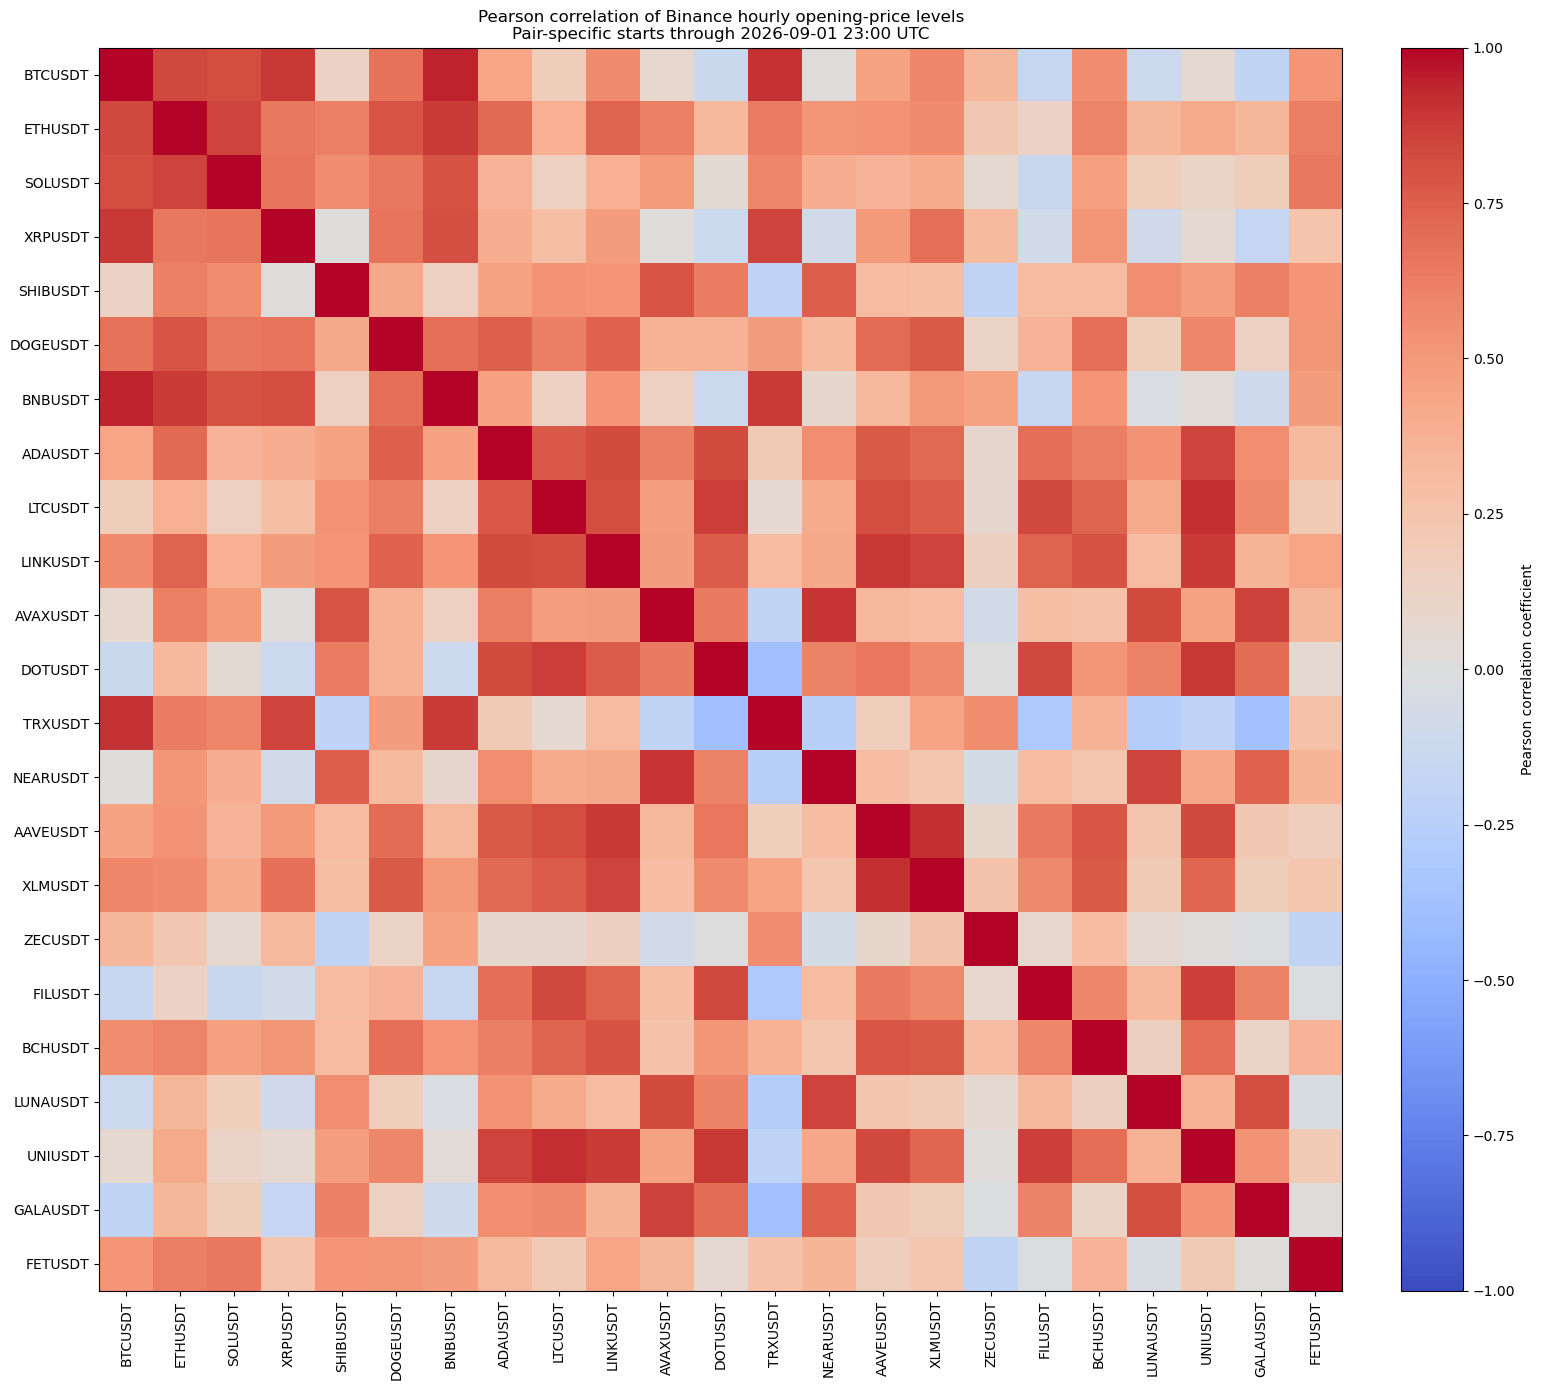

In [4]:
figure, axis = plt.subplots(figsize=(16, 14))
image = axis.imshow(correlation_matrix.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(len(selected_symbols)), labels=selected_symbols, rotation=90)
axis.set_yticks(range(len(selected_symbols)), labels=selected_symbols)
axis.set_title(
    "Pearson correlation of Binance hourly opening-price levels\n"
    "Pair-specific starts through 2026-09-01 23:00 UTC"
)
colorbar = figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
colorbar.set_label("Pearson correlation coefficient")
figure.tight_layout()
plt.show()

## Paired-observation counts

This matrix reports how many exact UTC timestamps support each coefficient. Its diagonal is the observation count for each individual asset. Off-diagonal values vary because assets were listed at different dates and because the raw series contain preserved gaps.

In [5]:
display(
    paired_observation_matrix.style
    .format("{:,}")
    .set_caption("Paired hourly observations through 2026-09-01 23:00 UTC used by each coefficient")
)

bitcoin_relationship = (
    pd.DataFrame(
        {
            "Pearson correlation with BTCUSDT": correlation_matrix[BTC_SYMBOL],
            "Paired observations": paired_observation_matrix[BTC_SYMBOL],
        }
    )
    .drop(index=BTC_SYMBOL)
    .sort_values("Pearson correlation with BTCUSDT", ascending=False)
)

display(
    bitcoin_relationship.style
    .format(
        {
            "Pearson correlation with BTCUSDT": "{:.4f}",
            "Paired observations": "{:,}",
        }
    )
    .background_gradient(subset=["Pearson correlation with BTCUSDT"], cmap="coolwarm", vmin=-1, vmax=1)
    .set_caption("Opening-price correlation with Bitcoin through 2026-09-01 23:00 UTC, highest to lowest")
)

,BTCUSDT,ETHUSDT,SOLUSDT,XRPUSDT,SHIBUSDT,DOGEUSDT,BNBUSDT,ADAUSDT,LTCUSDT,LINKUSDT,AVAXUSDT,DOTUSDT,TRXUSDT,NEARUSDT,AAVEUSDT,XLMUSDT,ZECUSDT,FILUSDT,BCHUSDT,LUNAUSDT,UNIUSDT,GALAUSDT,FETUSDT
BTCUSDT,"79,140","79,140","53,086","72,936","46,566","62,728","77,203","73,348","76,315","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
ETHUSDT,"79,140","79,140","53,086","72,936","46,566","62,728","77,203","73,348","76,315","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
SOLUSDT,"53,086","53,086","53,086","53,086","46,566","53,086","53,086","53,086","53,086","53,086","52,078","52,901","53,086","51,551","51,529","53,086","53,086","51,515","53,086","52,405","52,201","43,551","53,086"
XRPUSDT,"72,936","72,936","53,086","72,936","46,566","62,728","72,936","72,936","72,936","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
SHIBUSDT,"46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,129","46,566","43,551","46,566"
DOGEUSDT,"62,728","62,728","53,086","62,728","46,566","62,728","62,728","62,728","62,728","62,728","52,078","52,901","62,728","51,551","51,529","62,728","62,728","51,515","59,238","52,405","52,201","43,551","62,728"
BNBUSDT,"77,203","77,203","53,086","72,936","46,566","62,728","77,203","73,348","76,315","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
ADAUSDT,"73,348","73,348","53,086","72,936","46,566","62,728","73,348","73,348","73,348","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
LTCUSDT,"76,315","76,315","53,086","72,936","46,566","62,728","76,315","73,348","76,315","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
LINKUSDT,"66,794","66,794","53,086","66,794","46,566","62,728","66,794","66,794","66,794","66,794","52,078","52,901","66,794","51,551","51,529","66,794","65,270","51,515","59,238","52,405","52,201","43,551","65,762"


,Pearson correlation with BTCUSDT,Paired observations
BNBUSDT,0.9418,"77,203"
TRXUSDT,0.8990,"72,021"
XRPUSDT,0.8839,"72,936"
ETHUSDT,0.8348,"79,140"
SOLUSDT,0.8170,"53,086"
DOGEUSDT,0.6768,"62,728"
XLMUSDT,0.5866,"72,287"
LINKUSDT,0.5640,"66,794"
BCHUSDT,0.5624,"59,238"
FETUSDT,0.5200,"65,762"


## Interpretation limits

The matrix describes linear co-movement between **price levels**, as requested. It does not establish that Bitcoin directly causes another asset's price to change. Cryptocurrency price levels commonly trend over time and may be non-stationary, so a high coefficient can be driven by shared trends rather than a stable economic relationship.

The coefficients also use pair-specific overlap windows. A recently listed asset is compared with Bitcoin over a shorter and more recent market regime than a long-history asset. The paired-observation counts must therefore accompany the correlation matrix. These results should not be interpreted as predictive evidence or used directly in portfolio construction. A return-correlation analysis, stationarity assessment, rolling-window analysis, or lead-lag study would answer different questions and requires a separate methodology decision.